# Experiment 7: Implementation of a Simple Autoencoder


## Aim
To implement and train a simple Autoencoder for dimensionality reduction and feature learning using the MNIST handwritten digit dataset.

Dinesh Kumar P - 24BAD021

## Part A: Dataset preparation

Experiment 7: Autoencoder
Student Name: Dhanya G
Register Number: 24BAD019
TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)


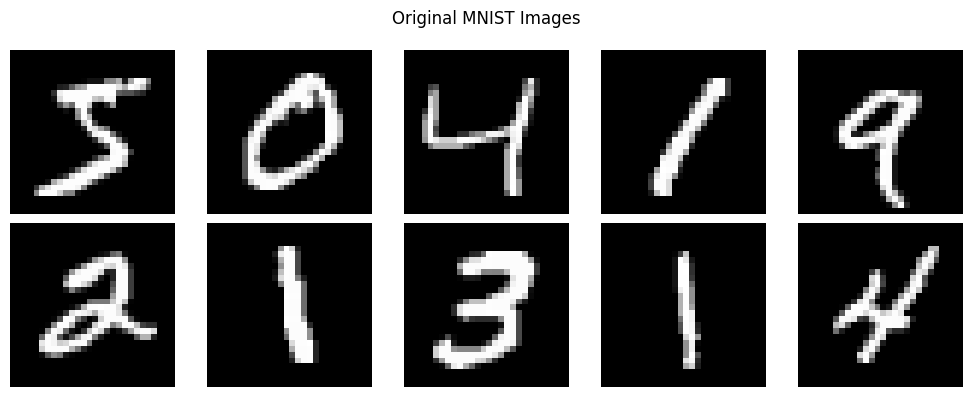

Dinesh Kumar P - 24BAD021


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

print("Experiment 7: Autoencoder")
print("Student Name: Dhanya G")
print("Register Number: 24BAD019")
print("TensorFlow version:", tf.__version__)

(x_train, _), (x_test, _) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Flattened training shape:", x_train.shape)
print("Flattened testing shape:", x_test.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()
print("Dinesh Kumar P - 24BAD021")

## Part B: Implementing the Autoencoder model

In [2]:
input_dim = 784
latent_dim = 16

input_layer = Input(shape=(input_dim,), name="Input_Layer")
encoded = Dense(128, activation="relu", name="Encoder_1")(input_layer)
encoded = Dense(32, activation="relu", name="Encoder_2")(encoded)
latent = Dense(latent_dim, activation="relu", name="Bottleneck")(encoded)

decoded = Dense(32, activation="relu", name="Decoder_1")(latent)
decoded = Dense(128, activation="relu", name="Decoder_2")(decoded)
output_layer = Dense(784, activation="sigmoid", name="Output_Layer")(decoded)

autoencoder = Model(input_layer, output_layer, name="Autoencoder")
encoder = Model(input_layer, latent, name="Encoder")
decoder_input = Input(shape=(latent_dim,), name="Decoder_Input")
decoder_hidden1 = autoencoder.get_layer("Decoder_1")(decoder_input)
decoder_hidden2 = autoencoder.get_layer("Decoder_2")(decoder_hidden1)
decoder_output = autoencoder.get_layer("Output_Layer")(decoder_hidden2)
decoder = Model(decoder_input, decoder_output, name="Decoder")

autoencoder.compile(optimizer="adam", loss="mean_squared_error")
autoencoder.summary()

try:
    tf.keras.utils.plot_model(autoencoder, show_shapes=True, show_layer_names=True)
except Exception as e:
    print("Model diagram could not be displayed:", e)
    print("Dinesh Kumar P - 24BAD021")

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_1 (Dense)               │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder_2 (Dense)               │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bottleneck (Dense)              │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_1 (Dense)               │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder_2 (Dense)               │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

## Part C: Training and performance evaluation

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0689 - val_loss: 0.0439
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0362 - val_loss: 0.0304
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0281 - val_loss: 0.0256
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.0247 - val_loss: 0.0231
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0225 - val_loss: 0.0214
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0211 - val_loss: 0.0202
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0199 - val_loss: 0.0190
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0190 - val_loss: 0.0183
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0184 - val_loss: 0.0179
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0179 - val_loss: 0.0174
Test reconstruction loss (MSE): 0.017371706664562225
Reconstruction Mean Squared Error: 0.017371714115142822
Final training loss:

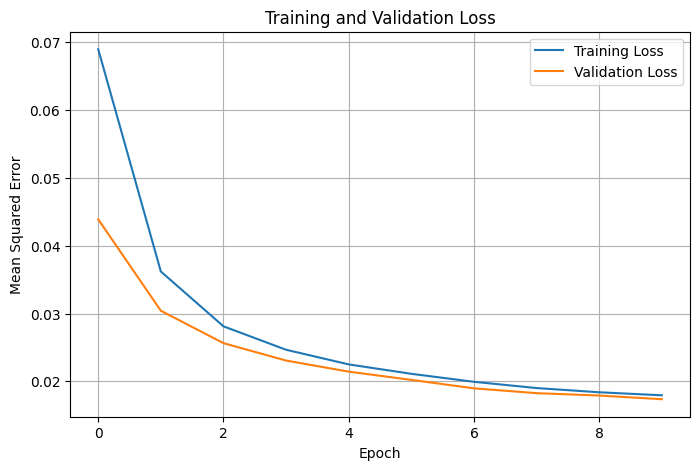

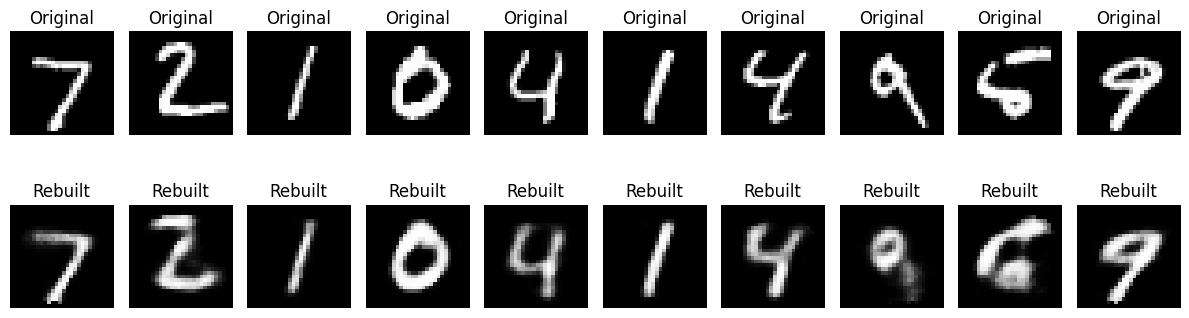

Dinesh Kumar P - 24BAD021


In [3]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)

test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
reconstructed_images = autoencoder.predict(x_test, verbose=0)
mse = mean_squared_error(x_test.flatten(), reconstructed_images.flatten())

print("Test reconstruction loss (MSE):", test_loss)
print("Reconstruction Mean Squared Error:", mse)
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap="gray")
    plt.title("Rebuilt")
    plt.axis("off")
plt.tight_layout()
plt.show()
print("Dinesh Kumar P - 24BAD021")

## Part D: Dimensionality reduction and feature visualization

The manual mentions movie-review sentences and an LSTM in Part D, but the experiment aim and earlier parts specify an MNIST image Autoencoder. This section uses the MNIST Autoencoder consistently.

Original dimensions: (1000, 784)
Compressed dimensions: (1000, 16)


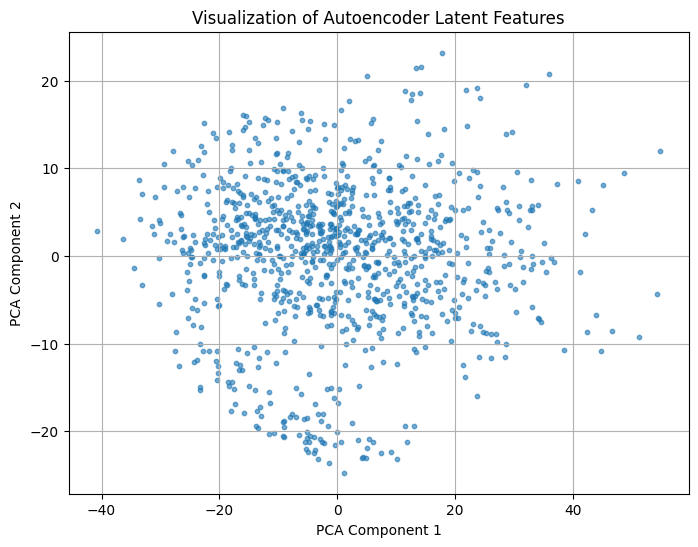

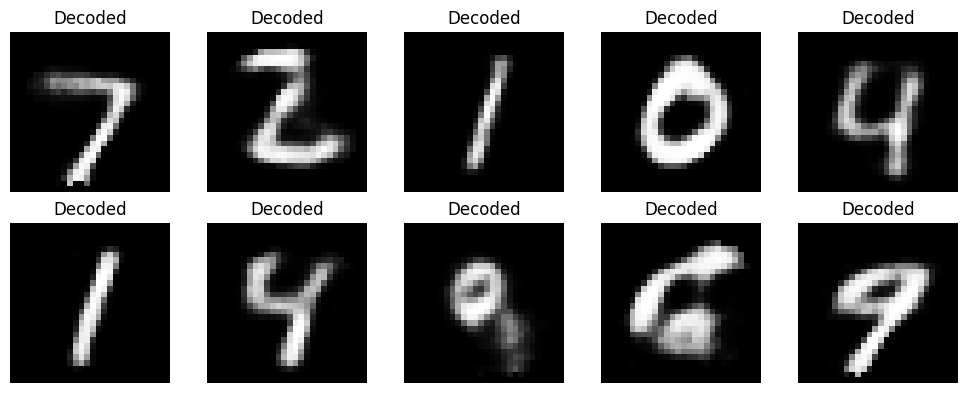

Dimensionality reduced from 784 values to 16 values per image.
Test reconstruction MSE: 0.017372
Dinesh Kumar P - 24BAD021


In [4]:
latent_features = encoder.predict(x_test[:1000], verbose=0)
print("Original dimensions:", x_test[:1000].shape)
print("Compressed dimensions:", latent_features.shape)

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))
plt.scatter(latent_2d[:, 0], latent_2d[:, 1], s=10, alpha=0.6)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Visualization of Autoencoder Latent Features")
plt.grid(True)
plt.show()

decoded_sample = decoder.predict(latent_features[:10], verbose=0)
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(decoded_sample[i].reshape(28, 28), cmap="gray")
    plt.title("Decoded")
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Dimensionality reduced from 784 values to", latent_dim, "values per image.")
print("Test reconstruction MSE:", round(float(mse), 6))
print("Dinesh Kumar P - 24BAD021")